In [1]:
!pip install requests beautifulsoup4 networkx pandas matplotlib seaborn scikit-learn

In [2]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import re
import time
from collections import Counter

In [3]:
START_URL = "https://www.youtube.com/"

MAX_PAGES = 50
TIMEOUT = 10

print("Target website:", START_URL)

Target website: https://www.youtube.com/


In [4]:
parsed_start = urlparse(START_URL)

DOMAIN = parsed_start.netloc

print("Domain:", DOMAIN)

Domain: www.youtube.com


In [5]:
def fetch_page(url):
    try:
        headers = {
            "User-Agent": "Mozilla/5.0 WebGraphAnalyzer/1.0"
        }

        response = requests.get(
            url,
            headers=headers,
            timeout=TIMEOUT
        )

        if response.status_code == 200:
            return response.text

        return None

    except Exception as e:
        print("Error:", url, e)
        return None

In [6]:
def normalize_url(url):
    parsed = urlparse(url)

    clean_url = parsed._replace(
        fragment="",
        query=""
    ).geturl()

    return clean_url.rstrip("/")

In [7]:
def is_internal(url):
    parsed = urlparse(url)

    return parsed.netloc == DOMAIN

In [8]:
def extract_links(html, current_url):

    soup = BeautifulSoup(html, "html.parser")

    links = set()

    for a in soup.find_all("a", href=True):

        href = a["href"]

        absolute_url = urljoin(current_url, href)

        absolute_url = normalize_url(absolute_url)

        if is_internal(absolute_url):
            links.add(absolute_url)

    return links

In [9]:
def extract_seo_data(html, url):

    soup = BeautifulSoup(html, "html.parser")

    title = soup.title.string.strip() if soup.title and soup.title.string else ""

    description_tag = soup.find(
        "meta",
        attrs={"name": "description"}
    )

    description = ""

    if description_tag:
        description = description_tag.get("content", "").strip()

    h1_tags = soup.find_all("h1")

    canonical_tag = soup.find(
        "link",
        rel="canonical"
    )

    canonical = ""

    if canonical_tag:
        canonical = canonical_tag.get("href", "")

    images = soup.find_all("img")

    images_without_alt = []

    for img in images:

        alt = img.get("alt")

        if not alt:
            images_without_alt.append(
                img.get("src", "")
            )

    word_count = len(
        soup.get_text(" ", strip=True).split()
    )

    return {
        "url": url,
        "title": title,
        "title_length": len(title),
        "description": description,
        "description_length": len(description),
        "h1_count": len(h1_tags),
        "canonical": canonical,
        "image_count": len(images),
        "images_without_alt": len(images_without_alt),
        "word_count": word_count
    }

In [10]:
pages_to_visit = [normalize_url(START_URL)]

visited_pages = set()

page_data = {}

edges = []

while pages_to_visit and len(visited_pages) < MAX_PAGES:

    current_url = pages_to_visit.pop(0)

    if current_url in visited_pages:
        continue

    print(
        f"Crawling {len(visited_pages)+1}/{MAX_PAGES}:",
        current_url
    )

    html = fetch_page(current_url)

    visited_pages.add(current_url)

    if html is None:
        continue

    seo = extract_seo_data(
        html,
        current_url
    )

    page_data[current_url] = seo

    links = extract_links(
        html,
        current_url
    )

    for link in links:

        edges.append(
            (current_url, link)
        )

        if (
            link not in visited_pages
            and link not in pages_to_visit
        ):
            pages_to_visit.append(link)

    time.sleep(0.5)

print("\nCrawling completed.")
print("Pages found:", len(visited_pages))
print("Links found:", len(edges))

Crawling 1/50: https://www.youtube.com
Crawling 2/50: https://www.youtube.com/about
Crawling 3/50: https://www.youtube.com/ads
Crawling 4/50: https://www.youtube.com/howyoutubeworks
Crawling 5/50: https://www.youtube.com/about/press
Crawling 6/50: https://www.youtube.com/about/copyright
Crawling 7/50: https://www.youtube.com/new
Crawling 8/50: https://www.youtube.com/t/privacy
Crawling 9/50: https://www.youtube.com/t/contact_us
Crawling 10/50: https://www.youtube.com/t/terms
Crawling 11/50: https://www.youtube.com/about/policies
Crawling 12/50: https://www.youtube.com/creators
Crawling 13/50: https://www.youtube.com/howyoutubeworks/our-policies
Crawling 14/50: https://www.youtube.com/premium
Crawling 15/50: https://www.youtube.com/howyoutubeworks/copyright
Crawling 16/50: https://www.youtube.com/channel/UCqVDpXKLmKeBU_yyt_QkItQ
Crawling 17/50: https://www.youtube.com/kids
Crawling 18/50: https://www.youtube.com/creators/research
Crawling 19/50: https://www.youtube.com/musicpremium
Craw

In [11]:
seo_df = pd.DataFrame(
    page_data.values()
)

seo_df.head()

,url,title,title_length,description,description_length,h1_count,canonical,image_count,images_without_alt,word_count
0,https://www.youtube.com,YouTube,7,"Enjoy the videos and music you love, upload or...",126,0,https://www.youtube.com/,0,0,27
1,https://www.youtube.com/about,About YouTube - YouTube,23,YouTube's mission is to give everyone a voice ...,122,1,https://about.youtube/,4,0,145
2,https://www.youtube.com/ads,,0,,0,0,,0,0,0
3,https://www.youtube.com/howyoutubeworks,How YouTube Works - Homepage - How YouTube Works,48,YouTube is home to unique voices and an array ...,147,1,https://www.youtube.com/howyoutubeworks/,12,0,619
4,https://www.youtube.com/about/press,Official YouTube Blog for Latest YouTube News ...,56,Explore our official blog for the latest news ...,150,1,https://blog.youtube/,51,7,2889


In [12]:
G = nx.DiGraph()

for url in visited_pages:
    G.add_node(url)

for source, target in edges:

    if (
        source in G.nodes
        and target in G.nodes
    ):
        G.add_edge(
            source,
            target
        )

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 50
Edges: 907


In [13]:
in_degree = dict(G.in_degree())

seo_df["in_degree"] = seo_df["url"].map(in_degree)

seo_df[
    ["url", "in_degree"]
].sort_values(
    "in_degree",
    ascending=False
).head(10)

,url,in_degree
9,https://www.youtube.com/t/terms,42
3,https://www.youtube.com/howyoutubeworks,41
11,https://www.youtube.com/creators,40
0,https://www.youtube.com,38
10,https://www.youtube.com/about/policies,37
2,https://www.youtube.com/ads,33
1,https://www.youtube.com/about,32
5,https://www.youtube.com/about/copyright,31
15,https://www.youtube.com/channel/UCqVDpXKLmKeBU...,26
13,https://www.youtube.com/premium,26


In [14]:
out_degree = dict(G.out_degree())

seo_df["out_degree"] = seo_df["url"].map(out_degree)

seo_df[
    ["url", "out_degree"]
].sort_values(
    "out_degree",
    ascending=False
).head(10)

,url,out_degree
45,https://www.youtube.com/howyoutubeworks/polici...,34
3,https://www.youtube.com/howyoutubeworks,33
12,https://www.youtube.com/howyoutubeworks/our-po...,33
5,https://www.youtube.com/about/copyright,33
14,https://www.youtube.com/howyoutubeworks/copyright,33
36,https://www.youtube.com/howyoutubeworks/learning,33
38,https://www.youtube.com/howyoutubeworks/ai,33
10,https://www.youtube.com/about/policies,33
30,https://www.youtube.com/howyoutubeworks/privacy,33
33,https://www.youtube.com/howyoutubeworks/elections,33


In [15]:
pagerank = nx.pagerank(G)

seo_df["pagerank"] = seo_df["url"].map(pagerank)

seo_df[
    ["url", "pagerank"]
].sort_values(
    "pagerank",
    ascending=False
).head(10)

,url,pagerank
0,https://www.youtube.com,0.117192
9,https://www.youtube.com/t/terms,0.068757
7,https://www.youtube.com/t/privacy,0.041952
3,https://www.youtube.com/howyoutubeworks,0.040611
11,https://www.youtube.com/creators,0.039726
10,https://www.youtube.com/about/policies,0.036164
2,https://www.youtube.com/ads,0.033009
1,https://www.youtube.com/about,0.032279
5,https://www.youtube.com/about/copyright,0.030665
4,https://www.youtube.com/about/press,0.023202


In [16]:
betweenness = nx.betweenness_centrality(
    G
)

seo_df["betweenness"] = seo_df["url"].map(
    betweenness
)

seo_df[
    ["url", "betweenness"]
].sort_values(
    "betweenness",
    ascending=False
).head(10)

,url,betweenness
4,https://www.youtube.com/about/press,0.218622
0,https://www.youtube.com,0.111727
3,https://www.youtube.com/howyoutubeworks,0.063311
10,https://www.youtube.com/about/policies,0.056520
5,https://www.youtube.com/about/copyright,0.049813
13,https://www.youtube.com/premium,0.041557
15,https://www.youtube.com/channel/UCqVDpXKLmKeBU...,0.041557
18,https://www.youtube.com/musicpremium,0.041557
11,https://www.youtube.com/creators,0.024277
1,https://www.youtube.com/about,0.023979


In [17]:
try:

    closeness = nx.closeness_centrality(G)

    seo_df["closeness"] = seo_df["url"].map(
        closeness
    )

except Exception as e:

    print(e)

In [18]:
orphan_pages = [
    node
    for node in G.nodes
    if G.in_degree(node) == 0
]

print("Orphan pages:", len(orphan_pages))

for page in orphan_pages:
    print(page)

Orphan pages: 0


In [19]:
dead_end_pages = [
    node
    for node in G.nodes
    if G.out_degree(node) == 0
]

print("Dead-end pages:", len(dead_end_pages))

for page in dead_end_pages:
    print(page)

Dead-end pages: 5
https://www.youtube.com/madeonyoutube
https://www.youtube.com/about/brand-resources
https://www.youtube.com/creator-and-artist-stories
https://www.youtube.com/ads/how-it-works/set-up-a-campaign/youtube-select
https://www.youtube.com/ads


In [20]:
seo_df["missing_title"] = (
    seo_df["title"].str.strip() == ""
)

seo_df["title_too_short"] = (
    seo_df["title_length"] < 30
)

seo_df["title_too_long"] = (
    seo_df["title_length"] > 60
)

seo_df[
    [
        "url",
        "title",
        "title_length",
        "missing_title",
        "title_too_short",
        "title_too_long"
    ]
]

,url,title,title_length,missing_title,title_too_short,title_too_long
0,https://www.youtube.com,YouTube,7,False,True,False
1,https://www.youtube.com/about,About YouTube - YouTube,23,False,True,False
2,https://www.youtube.com/ads,,0,True,True,False
3,https://www.youtube.com/howyoutubeworks,How YouTube Works - Homepage - How YouTube Works,48,False,False,False
4,https://www.youtube.com/about/press,Official YouTube Blog for Latest YouTube News ...,56,False,False,False
5,https://www.youtube.com/about/copyright,Copyright tools: Rightsholders and creators - ...,63,False,False,True
6,https://www.youtube.com/new,Labs page for YouTube,21,False,True,False
7,https://www.youtube.com/t/privacy,Privacy Policy – Privacy & Terms – Google,41,False,False,False
8,https://www.youtube.com/t/contact_us,Contact Us,10,False,True,False
9,https://www.youtube.com/t/terms,Terms of Service,16,False,True,False


In [21]:
seo_df["missing_description"] = (
    seo_df["description"].str.strip() == ""
)

seo_df["description_too_short"] = (
    seo_df["description_length"] < 70
)

seo_df["description_too_long"] = (
    seo_df["description_length"] > 160
)

seo_df[
    [
        "url",
        "description_length",
        "missing_description",
        "description_too_short",
        "description_too_long"
    ]
]

,url,description_length,missing_description,description_too_short,description_too_long
0,https://www.youtube.com,126,False,False,False
1,https://www.youtube.com/about,122,False,False,False
2,https://www.youtube.com/ads,0,True,True,False
3,https://www.youtube.com/howyoutubeworks,147,False,False,False
4,https://www.youtube.com/about/press,150,False,False,False
5,https://www.youtube.com/about/copyright,150,False,False,False
6,https://www.youtube.com/new,121,False,False,False
7,https://www.youtube.com/t/privacy,0,True,True,False
8,https://www.youtube.com/t/contact_us,0,True,True,False
9,https://www.youtube.com/t/terms,0,True,True,False


In [22]:
seo_df["missing_h1"] = (
    seo_df["h1_count"] == 0
)

seo_df["multiple_h1"] = (
    seo_df["h1_count"] > 1
)

seo_df[
    [
        "url",
        "h1_count",
        "missing_h1",
        "multiple_h1"
    ]
]

,url,h1_count,missing_h1,multiple_h1
0,https://www.youtube.com,0,True,False
1,https://www.youtube.com/about,1,False,False
2,https://www.youtube.com/ads,0,True,False
3,https://www.youtube.com/howyoutubeworks,1,False,False
4,https://www.youtube.com/about/press,1,False,False
5,https://www.youtube.com/about/copyright,1,False,False
6,https://www.youtube.com/new,0,True,False
7,https://www.youtube.com/t/privacy,14,False,True
8,https://www.youtube.com/t/contact_us,5,False,True
9,https://www.youtube.com/t/terms,13,False,True


In [23]:
seo_df[
    [
        "url",
        "image_count",
        "images_without_alt"
    ]
].sort_values(
    "images_without_alt",
    ascending=False
).head(20)

,url,image_count,images_without_alt
11,https://www.youtube.com/creators,120,76
29,https://www.youtube.com/creatorresearch,87,76
19,https://www.youtube.com/creators/podcasts,105,76
37,https://www.youtube.com/creators-for-change,120,76
34,https://www.youtube.com/nextup,120,76
17,https://www.youtube.com/creators/research,87,76
7,https://www.youtube.com/t/privacy,35,33
4,https://www.youtube.com/about/press,51,7
31,https://www.youtube.com/howyoutubeworks/youtub...,24,1
8,https://www.youtube.com/t/contact_us,1,0


In [24]:
def calculate_seo_score(row):

    score = 100

    if row["missing_title"]:
        score -= 20

    if row["title_too_short"] or row["title_too_long"]:
        score -= 10

    if row["missing_description"]:
        score -= 15

    if row["description_too_short"] or row["description_too_long"]:
        score -= 5

    if row["missing_h1"]:
        score -= 15

    if row["multiple_h1"]:
        score -= 5

    if row["images_without_alt"] > 0:
        score -= 10

    if row["in_degree"] == 0:
        score -= 20

    return max(score, 0)


seo_df["seo_score"] = seo_df.apply(
    calculate_seo_score,
    axis=1
)

seo_df[
    [
        "url",
        "seo_score"
    ]
].sort_values(
    "seo_score"
)

,url,seo_score
2,https://www.youtube.com/ads,35
32,https://www.youtube.com/ads/how-it-works/set-u...,35
40,https://www.youtube.com/feed,35
26,https://www.youtube.com/about/brand-resources,55
22,https://www.youtube.com/jobs,65
8,https://www.youtube.com/t/contact_us,65
9,https://www.youtube.com/t/terms,65
7,https://www.youtube.com/t/privacy,65
20,https://www.youtube.com/@360/featured,70
43,https://www.youtube.com/user/YouTube,70


In [25]:
def identify_issues(row):

    issues = []

    if row["missing_title"]:
        issues.append("Missing title")

    if row["title_too_long"]:
        issues.append("Long title")

    if row["title_too_short"]:
        issues.append("Short title")

    if row["missing_description"]:
        issues.append("Missing meta description")

    if row["missing_h1"]:
        issues.append("Missing H1")

    if row["multiple_h1"]:
        issues.append("Multiple H1")

    if row["images_without_alt"] > 0:
        issues.append("Images without ALT")

    if row["in_degree"] == 0:
        issues.append("Possible orphan page")

    if row["out_degree"] == 0:
        issues.append("Dead end")

    return ", ".join(issues)


seo_df["issues"] = seo_df.apply(
    identify_issues,
    axis=1
)

seo_df[
    ["url", "seo_score", "issues"]
]

,url,seo_score,issues
0,https://www.youtube.com,75,"Short title, Missing H1"
1,https://www.youtube.com/about,90,Short title
2,https://www.youtube.com/ads,35,"Missing title, Short title, Missing meta descr..."
3,https://www.youtube.com/howyoutubeworks,100,
4,https://www.youtube.com/about/press,90,Images without ALT
5,https://www.youtube.com/about/copyright,90,Long title
6,https://www.youtube.com/new,75,"Short title, Missing H1"
7,https://www.youtube.com/t/privacy,65,"Missing meta description, Multiple H1, Images ..."
8,https://www.youtube.com/t/contact_us,65,"Short title, Missing meta description, Multipl..."
9,https://www.youtube.com/t/terms,65,"Short title, Missing meta description, Multipl..."


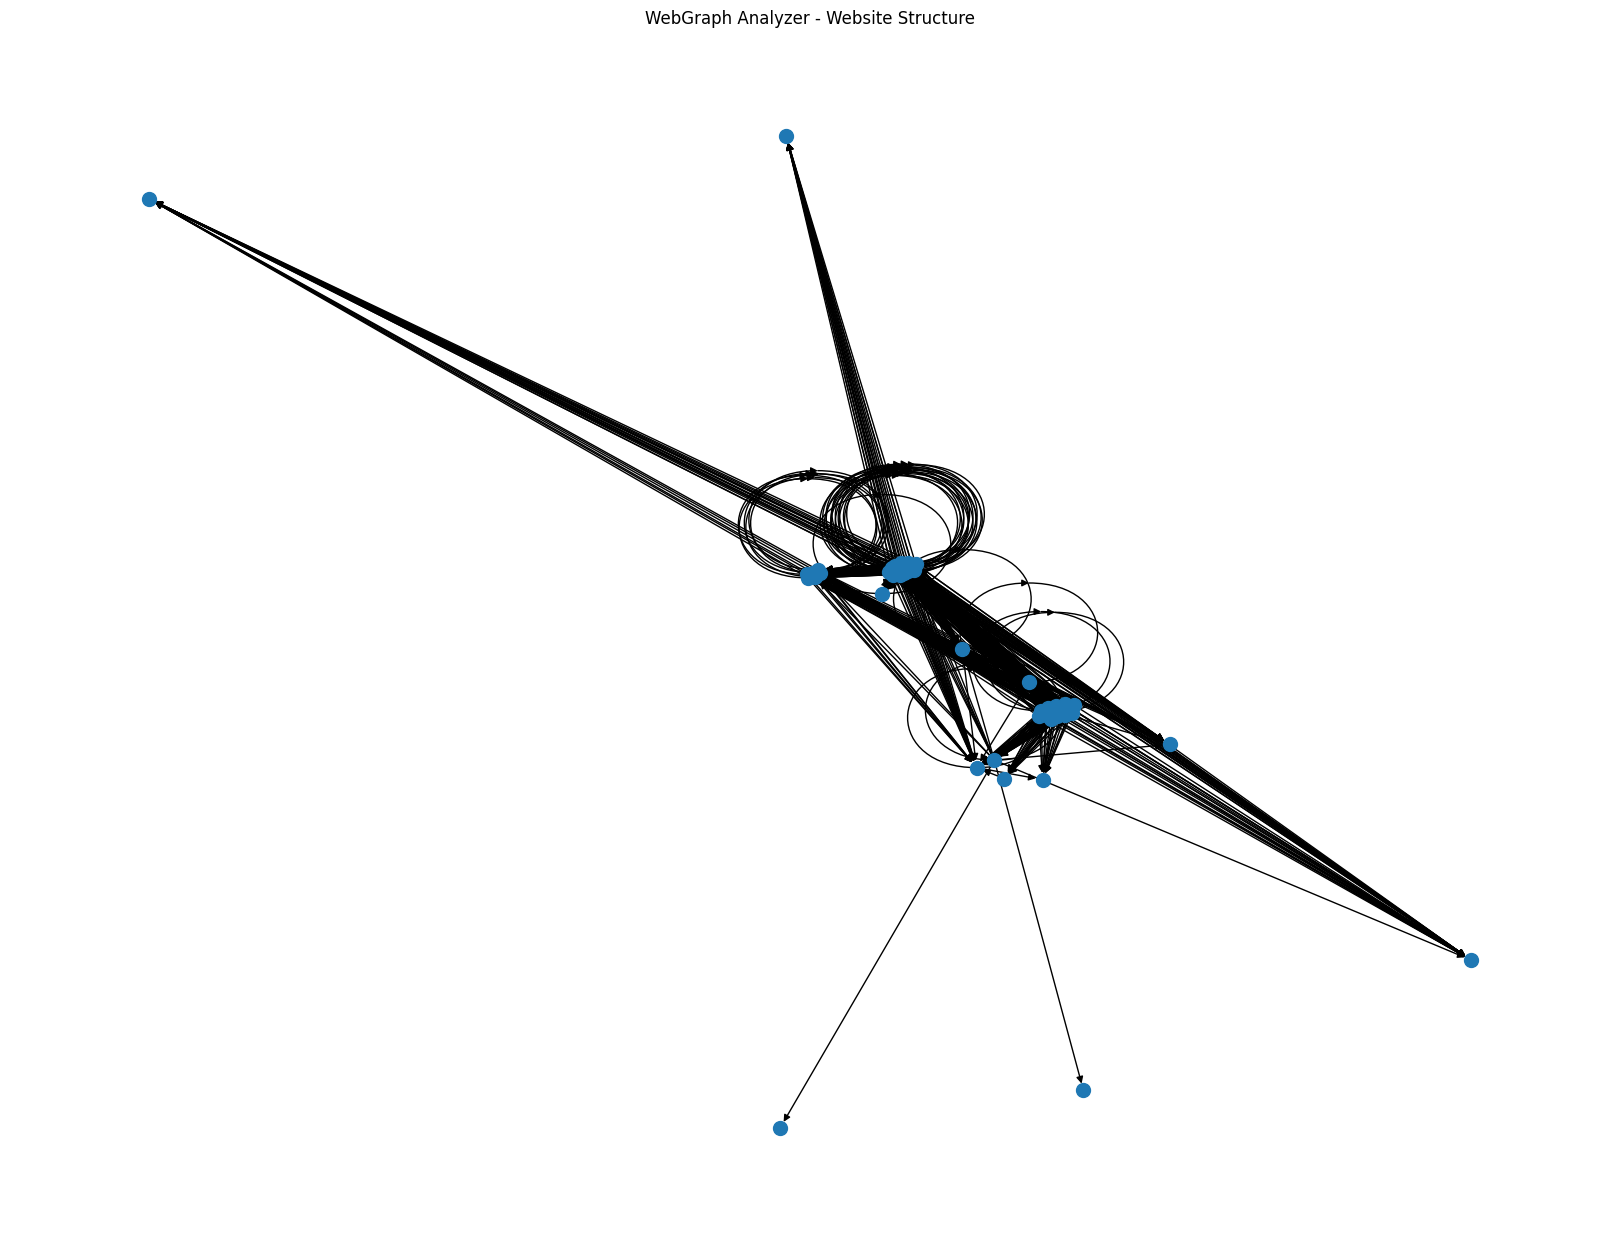

In [26]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw(
    G,
    pos,
    node_size=100,
    arrows=True,
    with_labels=False
)

plt.title(
    "WebGraph Analyzer - Website Structure"
)

plt.show()

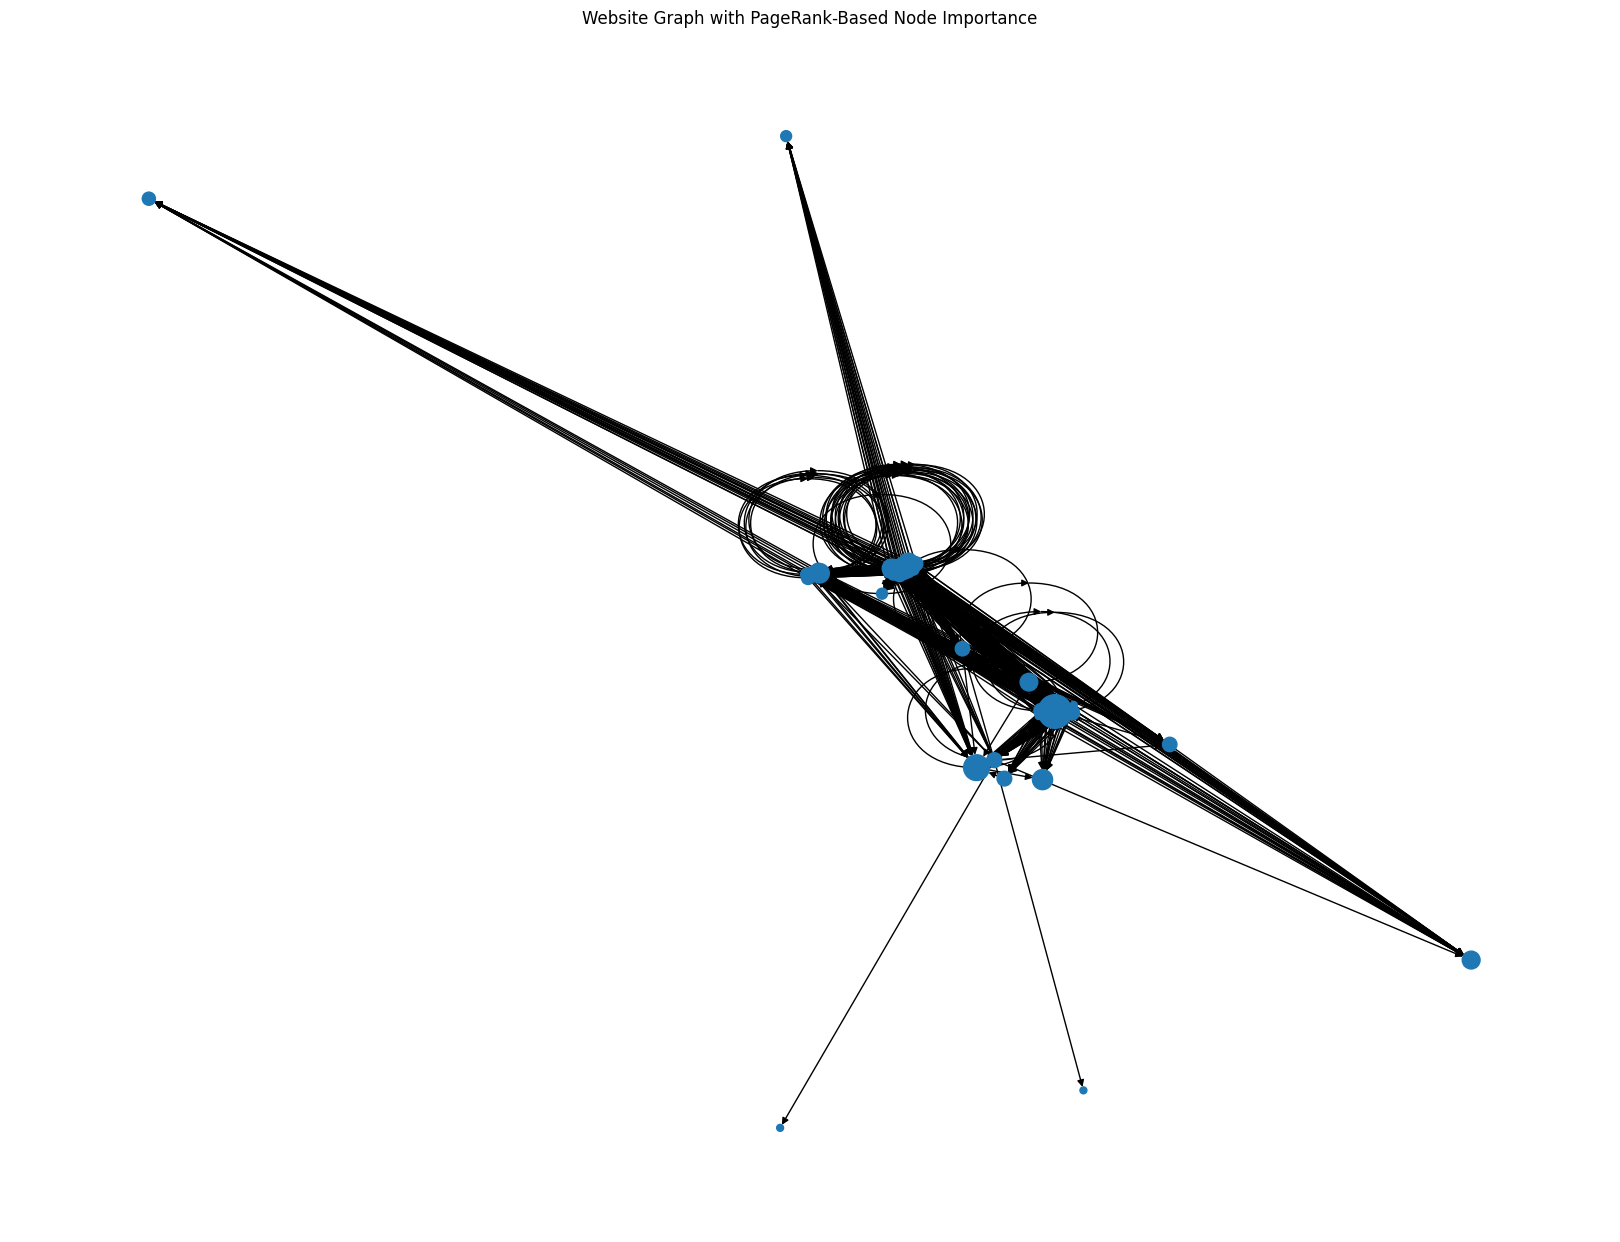

In [27]:
node_sizes = [
    5000 * pagerank.get(node, 0)
    for node in G.nodes
]

plt.figure(figsize=(16, 12))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw(
    G,
    pos,
    node_size=node_sizes,
    arrows=True,
    with_labels=False
)

plt.title(
    "Website Graph with PageRank-Based Node Importance"
)

plt.show()

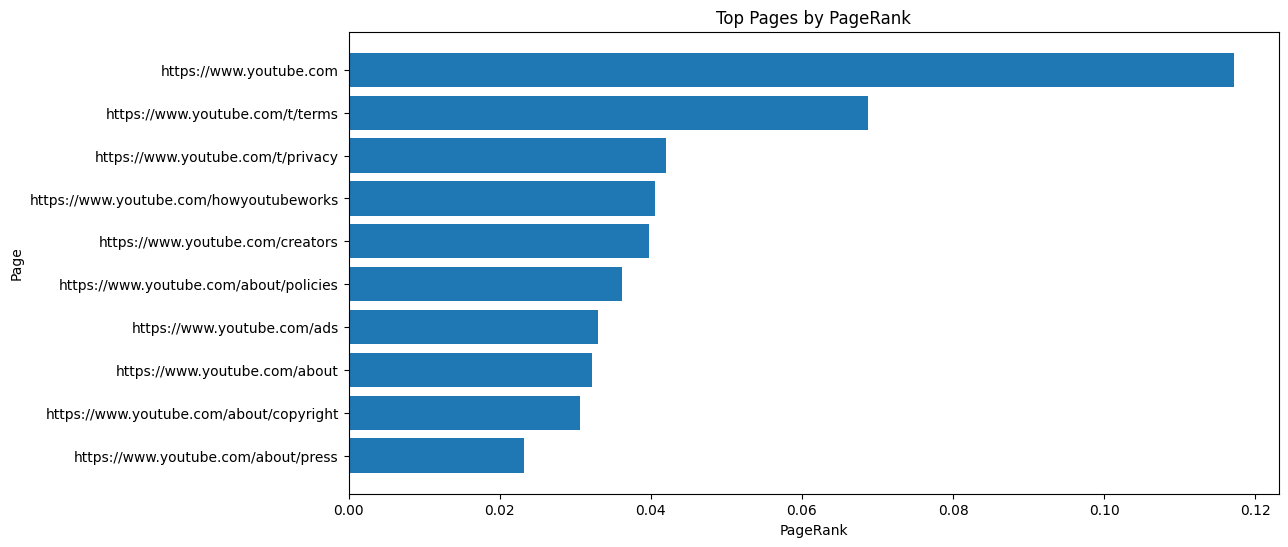

In [28]:
top_pages = seo_df.sort_values(
    "pagerank",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_pages["url"].str[-40:],
    top_pages["pagerank"]
)

plt.xlabel("PageRank")
plt.ylabel("Page")

plt.title(
    "Top Pages by PageRank"
)

plt.gca().invert_yaxis()

plt.show()

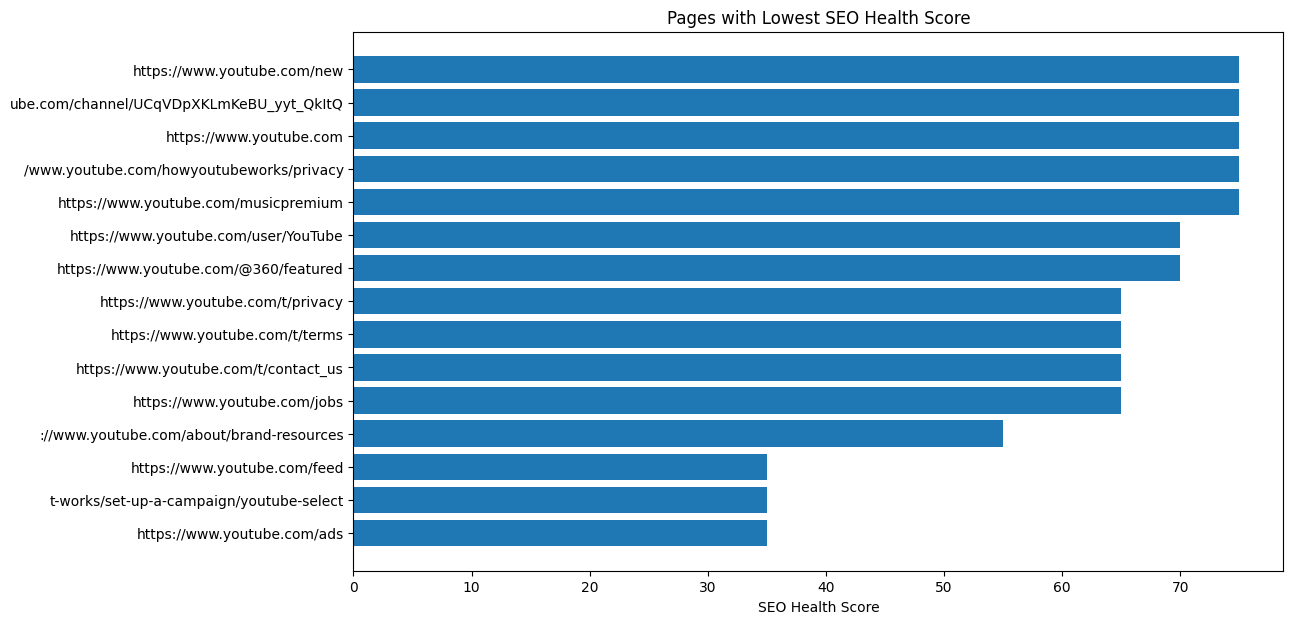

In [29]:
top_seo = seo_df.sort_values(
    "seo_score"
).head(15)

plt.figure(figsize=(12, 7))

plt.barh(
    top_seo["url"].str[-40:],
    top_seo["seo_score"]
)

plt.xlabel("SEO Health Score")

plt.title(
    "Pages with Lowest SEO Health Score"
)

plt.show()

In [30]:
print("===================================")
print("       WEBGRAPH ANALYZER")
print("===================================")

print("Website:", START_URL)

print("\nGRAPH STATISTICS")
print("----------------")
print("Pages:", G.number_of_nodes())
print("Links:", G.number_of_edges())

print("\nSEO STATISTICS")
print("----------------")

print(
    "Average SEO Score:",
    round(seo_df["seo_score"].mean(), 2)
)

print(
    "Missing Titles:",
    seo_df["missing_title"].sum()
)

print(
    "Missing Descriptions:",
    seo_df["missing_description"].sum()
)

print(
    "Missing H1:",
    seo_df["missing_h1"].sum()
)

print(
    "Possible Orphan Pages:",
    len(orphan_pages)
)

print(
    "Dead End Pages:",
    len(dead_end_pages)
)

       WEBGRAPH ANALYZER
Website: https://www.youtube.com/

GRAPH STATISTICS
----------------
Pages: 50
Links: 907

SEO STATISTICS
----------------
Average SEO Score: 80.52
Missing Titles: 3
Missing Descriptions: 8
Missing H1: 20
Possible Orphan Pages: 0
Dead End Pages: 5


In [31]:
report_columns = [
    "url",
    "title",
    "title_length",
    "description_length",
    "h1_count",
    "image_count",
    "images_without_alt",
    "word_count",
    "in_degree",
    "out_degree",
    "pagerank",
    "betweenness",
    "seo_score",
    "issues"
]

report = seo_df[report_columns].copy()

report.to_csv(
    "webgraph_seo_report.csv",
    index=False
)

print(
    "Report saved as webgraph_seo_report.csv"
)

Report saved as webgraph_seo_report.csv


In [32]:
dashboard = {
    "Website": START_URL,
    "Pages Crawled": G.number_of_nodes(),
    "Internal Links": G.number_of_edges(),
    "Average SEO Score": round(
        seo_df["seo_score"].mean(), 2
    ),
    "Orphan Pages": len(orphan_pages),
    "Dead End Pages": len(dead_end_pages),
    "Missing Titles": int(
        seo_df["missing_title"].sum()
    ),
    "Missing Descriptions": int(
        seo_df["missing_description"].sum()
    ),
    "Missing H1": int(
        seo_df["missing_h1"].sum()
    )
}

dashboard_df = pd.DataFrame(
    dashboard.items(),
    columns=["Metric", "Value"]
)

dashboard_df

,Metric,Value
0,Website,https://www.youtube.com/
1,Pages Crawled,50
2,Internal Links,907
3,Average SEO Score,80.52
4,Orphan Pages,0
5,Dead End Pages,5
6,Missing Titles,3
7,Missing Descriptions,8
8,Missing H1,20
